In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os

In [2]:
# 1. Dataset Path
path = os.path.expanduser("~/Downloads/Pneumonia X Ray")
path

'C:\\Users\\Vaishnavi/Downloads/Pneumonia X Ray'

In [3]:
# 2. Load Dataset
train = tf.keras.utils.image_dataset_from_directory(
    path + "/train",
    image_size=(150,150),
    batch_size=32,
    color_mode='grayscale',
    label_mode='binary'
)

test = tf.keras.utils.image_dataset_from_directory(
    path + "/test",
    image_size=(150,150),
    batch_size=32,
    color_mode='grayscale',
    label_mode='binary'
)

Found 3937 files belonging to 2 classes.
Found 624 files belonging to 2 classes.


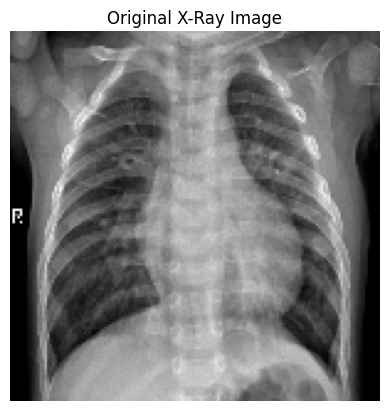

In [4]:
# 3. Display Original Image
for x, y in train.take(1):
    plt.imshow(x[0])
    plt.title("Original X-Ray Image")
    plt.axis('off')
    plt.show()

In [ ]:
# 4. Normalize Images
train = train.map(lambda x,y: (x/255.0, y))
test = test.map(lambda x,y: (x/255.0, y))

In [6]:


# 5. Build CNN Model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(150,150,1)),
    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

In [7]:
# 6. Compile Model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [8]:
# 7. Train Model
history = model.fit(
    train,
    epochs=5,
    validation_data=test
)


Epoch 1/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 79s 597ms/step - accuracy: 0.8885 - loss: 0.3194 - val_accuracy: 0.6603 - val_loss: 1.7271
Epoch 2/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 98s 787ms/step - accuracy: 0.9599 - loss: 0.1034 - val_accuracy: 0.7724 - val_loss: 0.7897
Epoch 3/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 103s 829ms/step - accuracy: 0.9703 - loss: 0.0727 - val_accuracy: 0.7708 - val_loss: 0.9300
Epoch 4/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 93s 739ms/step - accuracy: 0.9827 - loss: 0.0512 - val_accuracy: 0.7308 - val_loss: 1.0418
Epoch 5/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 88s 705ms/step - accuracy: 0.9876 - loss: 0.0382 - val_accuracy: 0.7196 - val_loss: 2.0618


In [9]:
# 8. Evaluate Model
loss, acc = model.evaluate(test)
print("\nTest Accuracy:", acc*100, "%")

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 198ms/step - accuracy: 0.7196 - loss: 2.0618

Test Accuracy: 71.95512652397156 %


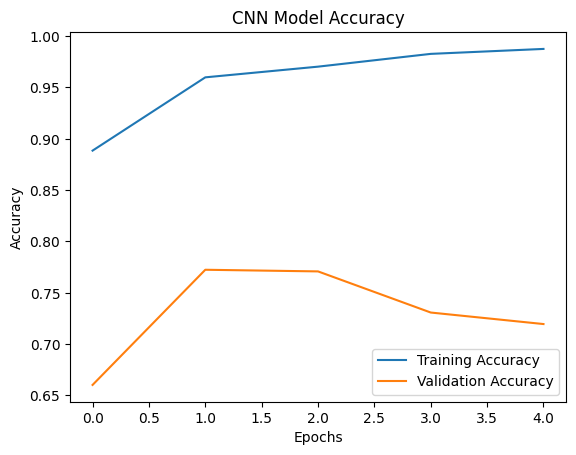

In [10]:
# 9. Plot Accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("CNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step


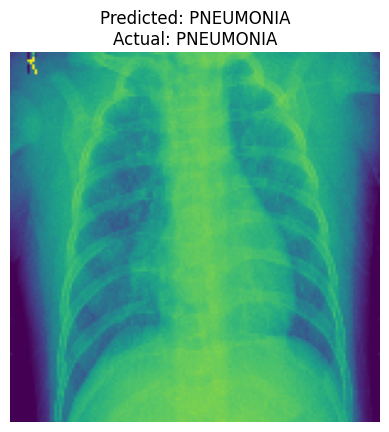

In [16]:
# 8. Display Image After Prediction
images, labels = next(iter(test))

prediction = model.predict(images[:1])

predicted_class = "PNEUMONIA" if prediction[0][0] > 0.5 else "NORMAL"
actual_class = "PNEUMONIA" if labels[0] == 1 else "NORMAL"

plt.imshow(images[0])
plt.title("Predicted: " + predicted_class +
          "\nActual: " + actual_class)
plt.axis("off")
plt.show()

In [13]:
1. What is CNN?

CNN stands for Convolutional Neural Network. It is a deep learning algorithm mainly used for image classification and computer vision. It automatically extracts features such as edges, shapes, and patterns from images.

2. Explain the working of your CNN model.

First, we load chest X-ray images and resize them to 150 × 150 pixels. Then convolutional layers extract image features, Max Pooling reduces dimensions, Flatten converts features into a one-dimensional vector, and Dense layers classify the image as NORMAL or PNEUMONIA.

3. What is a convolutional layer?

A convolutional layer applies filters or kernels over an image to extract important features such as edges, curves, and textures.

4. What is Max Pooling? Why is it used?

Max Pooling selects the maximum value from a small region of the feature map. It reduces image dimensions, computational cost, and retains important features.

5. What is Flatten?

Flatten converts multidimensional feature maps into a one-dimensional vector before passing them to the Dense layer.

6. What is the difference between ReLU and Sigmoid?

ReLU converts negative values into zero and keeps positive values unchanged. Sigmoid converts values into a probability between 0 and 1. ReLU is used in hidden layers, while Sigmoid is used in our binary classification output layer.

7. Why did you use Binary Crossentropy and Adam optimizer?

Binary Crossentropy calculates the prediction error for two classes. Adam is an optimizer that updates model weights efficiently to minimize the loss.

8. What is normalization and why is it required?

Normalization scales pixel values from 0–255 to 0–1 by dividing them by 255. It helps make model training more stable.

9. What is an epoch and batch size?

An epoch means one complete pass through the training dataset. Batch size is the number of images processed before updating the model weights. We used 5 epochs and a batch size of 32.

10. What is overfitting?

Overfitting occurs when a model performs very well on training data but poorly on unseen data because it learns training-specific patterns instead of generalizing.

11. What is RNN? Explain its working.

RNN stands for Recurrent Neural Network. It is used for sequential data such as text, speech, and time series. It processes input one step at a time and passes information from the previous hidden state to the next step.







medium.com


For example, in the sentence "I love deep learning", RNN processes each word sequentially and remembers information from previous words using its hidden state.

12. What is the difference between CNN and RNN?

CNN is mainly used for image processing and extracts spatial features using filters. RNN is used for sequential data and remembers previous information using hidden states.

13. What is LSTM?

LSTM stands for Long Short-Term Memory. It is an improved version of RNN that can remember important information for longer sequences using three gates: Forget Gate, Input Gate, and Output Gate.

14. What is backpropagation?

Backpropagation is a process in which the model calculates errors and sends them backward through the network to update weights and improve predictions

SyntaxError: invalid character '×' (U+00D7) (4039610374.py, line 7)